In [1]:
import pandas as pd
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve,f1_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('MIC_processing.csv')
df 

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,77.0,1,2.0,1.000000,1.000000,2.000000,3.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
1,55.0,1,1.0,0.000000,0.000000,0.000000,0.0,0.0,0.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
2,52.0,1,0.0,0.000000,0.000000,2.000000,2.0,0.0,2.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
3,68.0,0,0.0,0.000000,0.000000,2.000000,2.0,0.0,3.00000,1.000000,...,0,0,0,0,0,0,1,0,0,0
4,60.0,1,0.0,0.000000,0.000000,2.000000,3.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1695,77.0,0,0.0,4.000000,2.000000,1.000000,2.0,0.0,7.00000,0.000000,...,0,0,1,0,1,0,0,0,0,1
1696,70.0,0,0.0,6.000000,2.000000,1.000000,2.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,1
1697,55.0,1,3.0,6.000000,2.000000,2.000000,0.0,0.0,0.00000,0.000000,...,0,0,0,0,0,0,0,1,0,1
1698,79.0,0,2.0,2.000000,2.000000,1.000000,2.0,0.0,7.00000,0.194411,...,0,0,0,1,0,0,0,0,0,1


In [2]:
X = df.drop(columns=['LET_IS']) 
y = df['LET_IS']  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression()

# 训练模型
model.fit(X_train, y_train)

# 预测
y_pred = model.predict(X_test)  # 预测类别
y_pred_proba = model.predict_proba(X_test)[:, 1]  # 预测概率（用于ROC曲线）

# 评估模型
accuracy = accuracy_score(y_test, y_pred)

In [3]:
accuracy

0.9

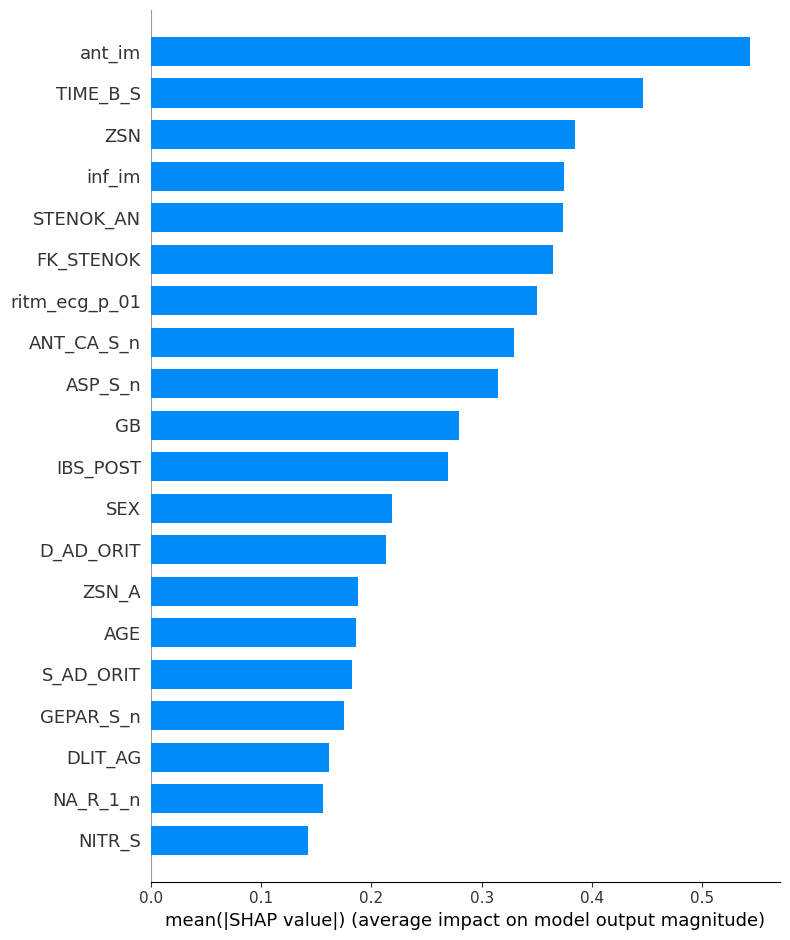

In [4]:
import shap
import time
s = time.time()
explainer = shap.Explainer(model,X_train)
shap_values = explainer.shap_values(X_train)
feature_names = X_train.columns.tolist()
shap.summary_plot(shap_values, X_train, plot_type="bar", feature_names=feature_names)

In [5]:
e = time.time()
e-s

0.09509086608886719

In [5]:
shap_values = explainer.shap_values(X_train)
feature_importance = np.abs(shap_values).mean(axis=0)
sorted_feature_indices = np.argsort(feature_importance)[::-1]
sorted_features = X_train.columns[sorted_feature_indices][:30]
sorted_features

Index(['ant_im', 'TIME_B_S', 'ZSN', 'inf_im', 'STENOK_AN', 'FK_STENOK',
       'ritm_ecg_p_01', 'ANT_CA_S_n', 'ASP_S_n', 'GB', 'IBS_POST', 'SEX',
       'D_AD_ORIT', 'ZSN_A', 'AGE', 'S_AD_ORIT', 'GEPAR_S_n', 'DLIT_AG',
       'NA_R_1_n', 'NITR_S', 'L_BLOOD', 'lat_im', 'ROE', 'ritm_ecg_p_07',
       'LID_S_n', 'P_IM_STEN', 'RAZRIV', 'endocr_01', 'B_BLOK_S_n', 'REC_IM'],
      dtype='object')

In [15]:
shap_df = pd.DataFrame(shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)

In [ ]:
shap_values_per_feature_sorted

ant_im          5.431633e-01
TIME_B_S        4.457210e-01
ZSN             3.847631e-01
inf_im          3.749525e-01
STENOK_AN       3.737813e-01
                    ...     
n_p_ecg_p_04    7.521400e-06
fibr_ter_08     5.260719e-06
n_p_ecg_p_05    3.636627e-06
nr_07           2.961530e-06
np_07           1.188276e-09
Length: 111, dtype: float64

In [52]:
print(shap_values_per_feature_sorted[:30])

ant_im           0.543163
TIME_B_S         0.445721
ZSN              0.384763
inf_im           0.374952
STENOK_AN        0.373781
FK_STENOK        0.364769
ritm_ecg_p_01    0.349678
ANT_CA_S_n       0.328906
ASP_S_n          0.314674
GB               0.279266
IBS_POST         0.269135
SEX              0.219105
D_AD_ORIT        0.213369
ZSN_A            0.187490
AGE              0.186078
S_AD_ORIT        0.182495
GEPAR_S_n        0.175541
DLIT_AG          0.161166
NA_R_1_n         0.155875
NITR_S           0.142436
L_BLOOD          0.128282
lat_im           0.119429
ROE              0.102956
ritm_ecg_p_07    0.090359
LID_S_n          0.088296
P_IM_STEN        0.087688
RAZRIV           0.085545
endocr_01        0.082071
B_BLOK_S_n       0.073271
REC_IM           0.068098
dtype: float64


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# Generate the summary plot with bar chart
# shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=False)
shap_values_per_feature_normalized

ant_im          1.000000
TIME_B_S        0.820602
ZSN             0.708375
inf_im          0.690313
STENOK_AN       0.688156
                  ...   
n_p_ecg_p_04    0.000014
fibr_ter_08     0.000010
n_p_ecg_p_05    0.000007
nr_07           0.000005
np_07           0.000000
Length: 111, dtype: float64

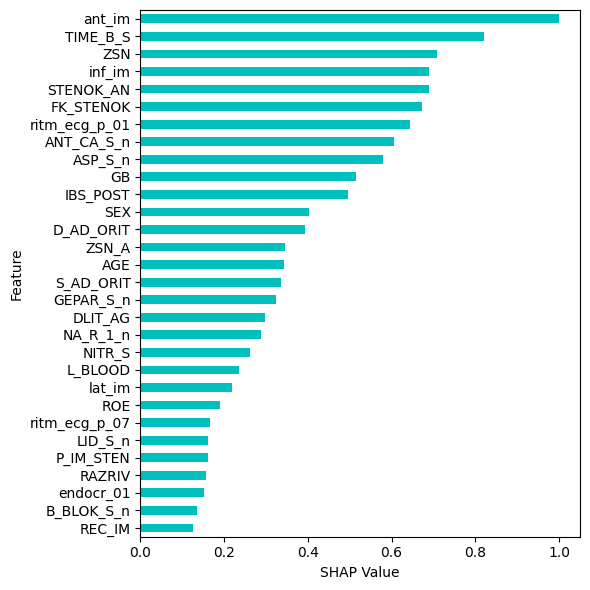

In [55]:
# Create a vertical figure for better spacing
plt.figure(figsize=(6, 6))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized[:30].plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_mic_lr_normalized.eps', format='eps', dpi=300)

plt.show()

In [7]:
import time
s = time.time()

from lime import lime_tabular
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt

# 创建 LIME 解释器
explainer = LimeTabularExplainer(X_test.values,
                                 feature_names=X_train.columns.tolist(),
                                 mode='classification')

# 选择一个测试样本
sample_idx = 0  # 选择测试集的索引
exp = explainer.explain_instance(X_test.iloc[sample_idx].values, model.predict_proba, num_features=len(X_test.columns))

# 提取特征值及其权重
feature_values = exp.as_list()

feature_values

[('RAZRIV <= 0.00', -0.16999688767576063),
 ('ZSN_A <= 0.00', -0.10216933128335799),
 ('1.00 < ant_im <= 4.00', 0.09163866615547571),
 ('ZSN > 0.00', -0.07344554899830902),
 ('ASP_S_n <= 0.74', 0.07061769744163789),
 ('0.00 < ritm_ecg_p_01 <= 1.00', -0.06522923373974668),
 ('inf_im <= 0.00', -0.0646728439078898),
 ('0.00 < ANT_CA_S_n <= 1.00', -0.06180902954450895),
 ('NITR_S <= 0.00', -0.06117298325007291),
 ('FK_STENOK <= 0.00', 0.06053141366952309),
 ('STENOK_AN <= 0.00', -0.05961851892413853),
 ('REC_IM <= 0.00', -0.05114612687589997),
 ('endocr_03 <= 0.00', -0.04563557176763707),
 ('1.00 < IBS_POST <= 2.00', 0.044661673587406386),
 ('P_IM_STEN <= 0.00', 0.044226540019175614),
 ('lat_im > 1.00', 0.04076566122169319),
 ('np_09 <= 0.00', 0.039264771119806315),
 ('SEX <= 0.00', 0.03919608526613094),
 ('ROE > 18.00', 0.03511219372619833),
 ('zab_leg_03 <= 0.00', -0.034840273630247866),
 ('GEPAR_S_n <= 0.00', 0.033931284625618015),
 ('R_AB_3_n <= 0.00', -0.032951541669162976),
 ('0.00 <

In [8]:
e = time.time()
e-s

0.19272089004516602

In [29]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [X_test.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")

Feature: RAZRIV, Weight: 0.17264788444508364
Feature: ZSN_A, Weight: 0.11976577201859878
Feature: ant_im, Weight: 0.08881873176671909
Feature: ZSN, Weight: 0.07493287183743226
Feature: ritm_ecg_p_01, Weight: 0.07072973164583321
Feature: ANT_CA_S_n, Weight: 0.06546331291812585
Feature: inf_im, Weight: 0.06543820091227968
Feature: STENOK_AN, Weight: 0.064929355886508
Feature: FK_STENOK, Weight: 0.060988081375296245
Feature: ASP_S_n, Weight: 0.05990287640305392
Feature: NITR_S, Weight: 0.05190052977602894
Feature: P_IM_STEN, Weight: 0.050727996147151566
Feature: SEX, Weight: 0.04400458789777614
Feature: endocr_03, Weight: 0.04327897464996035
Feature: IBS_POST, Weight: 0.03968583449532488
Feature: R_AB_3_n, Weight: 0.038893469196886625
Feature: TIME_B_S, Weight: 0.03884867874926801
Feature: endocr_01, Weight: 0.038015573554363725
Feature: REC_IM, Weight: 0.036373045351599444
Feature: lat_im, Weight: 0.03568226104440564
Feature: GEPAR_S_n, Weight: 0.034485725504891984
Feature: np_04, Weight

In [30]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.6934620442950421,
 0.5140735513123154,
 0.43358238103529034,
 0.4092183391550564,
 0.3786908666959721,
 0.37854530172924655,
 0.3755957161924069,
 0.35274961235685304,
 0.34645908237519873,
 0.3000724525048277,
 0.2932757107504008,
 0.2543026114250192,
 0.25009650105211945,
 0.22926840272124183,
 0.2246753555147319,
 0.22441572193320267,
 0.21958652068508383,
 0.21006539502727187,
 0.2060611750813568,
 0.19912530316964494,
 0.18528977653759313,
 0.18389051988458824,
 0.17875615321966679,
 0.1762486335020447,
 0.17264846398887881,
 0.15725393994743833,
 0.14724082689312,
 0.14557127780010165,
 0.1393898443680854,
 0.1365286663881014,
 0.13516171803101784,
 0.12953257286668687,
 0.12905295163494404,
 0.12787839778936982,
 0.12541084533821878,
 0.12317465103180283,
 0.11934689876259129,
 0.11848482187827798,
 0.11847921255851938,
 0.10104053759889044,
 0.096655152152931,
 0.09612656520048735,
 0.09120775427366888,
 0.09017859025909417,
 0.08612762281798583,
 0.08231468486816804,


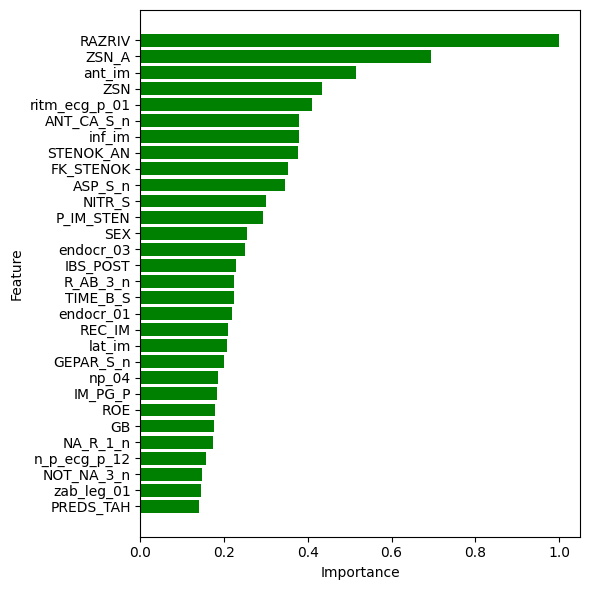

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(6, 6))
plt.barh(features[:30], normalized_weights[:30], color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('lime_mic_lr_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [9]:
import time
s = time.time()

from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(X_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature RAZRIV (0.015294)
2. feature ZSN (0.008824)
3. feature ant_im (0.008529)
4. feature D_AD_ORIT (0.007353)
5. feature lat_im (0.006765)
6. feature S_AD_ORIT (0.006765)
7. feature GB (0.006471)
8. feature TIME_B_S (0.005000)
9. feature IBS_POST (0.004412)
10. feature ROE (0.004118)
11. feature R_AB_3_n (0.004118)
12. feature NA_R_1_n (0.003824)
13. feature NA_R_2_n (0.003529)
14. feature REC_IM (0.003529)
15. feature NOT_NA_3_n (0.003235)
16. feature NOT_NA_2_n (0.002941)
17. feature STENOK_AN (0.002647)
18. feature R_AB_1_n (0.002647)
19. feature n_r_ecg_p_04 (0.002647)
20. feature AST_BLOOD (0.002647)
21. feature ritm_ecg_p_07 (0.002353)
22. feature LID_S_n (0.002353)
23. feature DRESSLER (0.002059)
24. feature ritm_ecg_p_01 (0.001765)
25. feature L_BLOOD (0.001765)
26. feature SEX (0.001765)
27. feature ALT_BLOOD (0.001765)
28. feature AGE (0.001471)
29. feature IM_PG_P (0.001176)
30. feature DLIT_AG (0.000882)
31. feature O_L_POST (0.000882)
32. feature INF

In [10]:
e = time.time()
e-s

1.0937600135803223

In [35]:
from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, X_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(X_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature RAZRIV (0.017647)
2. feature S_AD_ORIT (0.014706)
3. feature AGE (0.011765)
4. feature D_AD_ORIT (0.011765)
5. feature TIME_B_S (0.008824)
6. feature ritm_ecg_p_01 (0.008824)
7. feature ROE (0.008824)
8. feature ZSN (0.008824)
9. feature SEX (0.008824)
10. feature ALT_BLOOD (0.005882)
11. feature R_AB_3_n (0.005882)
12. feature NA_R_2_n (0.005882)
13. feature ritm_ecg_p_07 (0.002941)
14. feature NA_R_1_n (0.002941)
15. feature n_r_ecg_p_04 (0.002941)
16. feature DRESSLER (0.002941)
17. feature AST_BLOOD (0.002941)
18. feature n_r_ecg_p_01 (0.002941)
19. feature R_AB_1_n (0.002941)
20. feature ASP_S_n (0.002941)
21. feature NITR_S (0.002941)
22. feature FIBR_PREDS (0.002941)
23. feature post_im (0.002941)
24. feature NOT_NA_2_n (0.002941)
25. feature IM_PG_P (0.002941)
26. feature LID_S_n (0.002941)
27. feature REC_IM (0.002941)
28. feature zab_leg_03 (0.000000)
29. feature ant_im (0.000000)
30. feature FIB_G_POST (0.000000)
31. feature GT_POST (0.000000)
32.

In [37]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(X_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature RAZRIV (1.000000)
2. feature S_AD_ORIT (0.900000)
3. feature AGE (0.800000)
4. feature D_AD_ORIT (0.800000)
5. feature TIME_B_S (0.700000)
6. feature ritm_ecg_p_01 (0.700000)
7. feature ROE (0.700000)
8. feature ZSN (0.700000)
9. feature SEX (0.700000)
10. feature ALT_BLOOD (0.600000)
11. feature R_AB_3_n (0.600000)
12. feature NA_R_2_n (0.600000)
13. feature ritm_ecg_p_07 (0.500000)
14. feature NA_R_1_n (0.500000)
15. feature n_r_ecg_p_04 (0.500000)
16. feature DRESSLER (0.500000)
17. feature AST_BLOOD (0.500000)
18. feature n_r_ecg_p_01 (0.500000)
19. feature R_AB_1_n (0.500000)
20. feature ASP_S_n (0.500000)
21. feature NITR_S (0.500000)
22. feature FIBR_PREDS (0.500000)
23. feature post_im (0.500000)
24. feature NOT_NA_2_n (0.500000)
25. feature IM_PG_P (0.500000)
26. feature LID_S_n (0.500000)
27. feature REC_IM (0.500000)
28. feature zab_leg_03 (0.400000)
29. feature ant_im (0.400000)
30. feature FIB_G_POST (0.400000)
31. featur

In [43]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

sorted_feature_importance_30 = sorted_feature_importance_df[:30]
sorted_feature_importance_30

,Feature,Importance,Std
0,RAZRIV,1.0,0.0
1,S_AD_ORIT,0.9,0.0
2,AGE,0.8,0.0
3,D_AD_ORIT,0.8,0.0
4,TIME_B_S,0.7,0.0
5,ritm_ecg_p_01,0.7,0.0
6,ROE,0.7,0.0
7,ZSN,0.7,0.0
8,SEX,0.7,0.0
11,NA_R_2_n,0.6,0.0


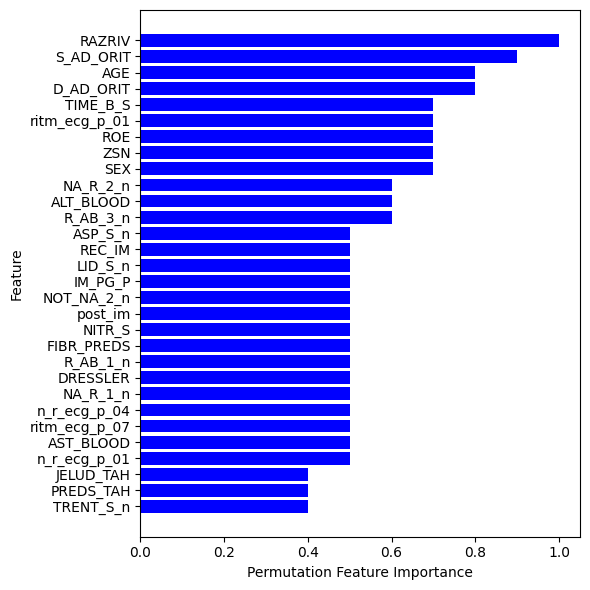

In [46]:
# 画图
plt.figure(figsize=(6, 6))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_30['Feature'], sorted_feature_importance_30['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部


# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_mic_lr_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

100%|██████████| 1360/1360 [1:31:07<00:00,  4.02s/it]


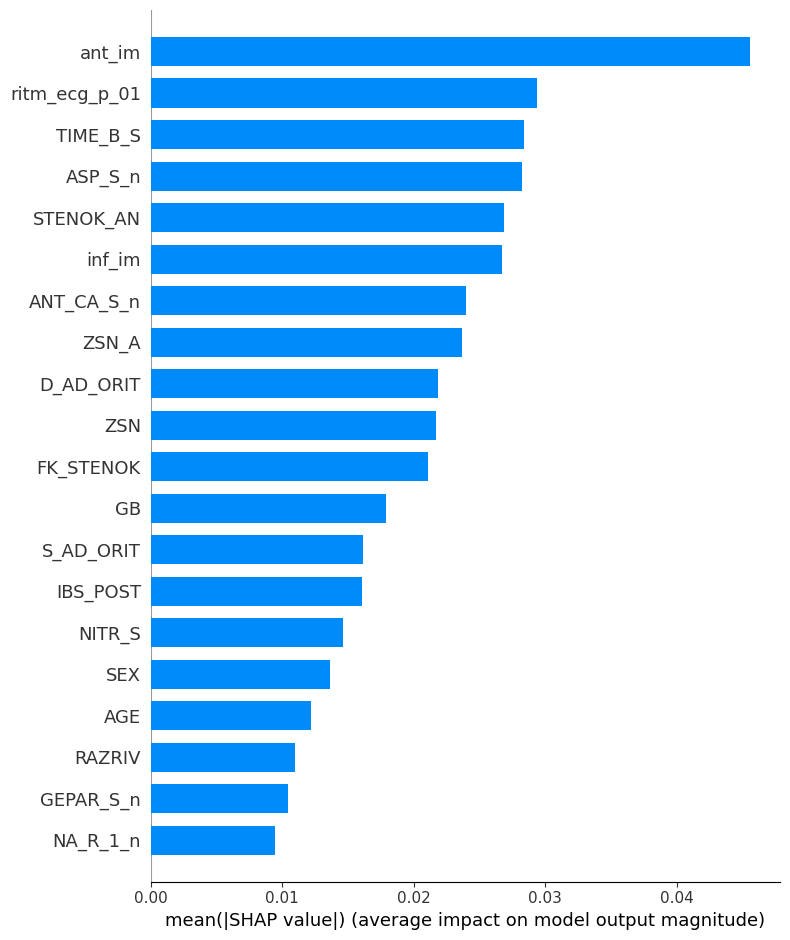

In [62]:
# 使用 SHAP 解释模型
import time

s= time.time()
Sampling_explainer = shap.SamplingExplainer(model.predict, X_train) 
Sampling_shap_values = Sampling_explainer.shap_values(X_train) 

# 获取特征名称
feature_names = X_train.columns.tolist()

# 绘制 SHAP 摘要图
shap.summary_plot(Sampling_shap_values, X_train, plot_type="bar", feature_names=feature_names)

In [63]:
e = time.time()
e-s

5467.872638940811

In [64]:
# shap_values = explainer.shap_values(X_test)
Samplingfeature_importance = np.abs(Sampling_shap_values).mean(axis=0)
Samplingsorted_feature_indices = np.argsort(Samplingfeature_importance)[::-1]
Samplingsorted_features = X_train.columns[Samplingsorted_feature_indices][:30]
Samplingsorted_features

Index(['ant_im', 'ritm_ecg_p_01', 'TIME_B_S', 'ASP_S_n', 'STENOK_AN', 'inf_im',
       'ANT_CA_S_n', 'ZSN_A', 'D_AD_ORIT', 'ZSN', 'FK_STENOK', 'GB',
       'S_AD_ORIT', 'IBS_POST', 'NITR_S', 'SEX', 'AGE', 'RAZRIV', 'GEPAR_S_n',
       'NA_R_1_n', 'DLIT_AG', 'L_BLOOD', 'lat_im', 'ritm_ecg_p_07', 'ROE',
       'endocr_01', 'REC_IM', 'R_AB_3_n', 'O_L_POST', 'LID_S_n'],
      dtype='object')

In [76]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(Sampling_shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)
shap_values_per_feature_sorted

ant_im           0.045562
ritm_ecg_p_01    0.029375
TIME_B_S         0.028391
ASP_S_n          0.028221
STENOK_AN        0.026830
                   ...   
fibr_ter_05      0.000000
fibr_ter_06      0.000000
nr_07            0.000000
np_04            0.000000
n_p_ecg_p_04     0.000000
Length: 111, dtype: float64

In [77]:
shap_values_per_feature_sorted[:30]

ant_im           0.045562
ritm_ecg_p_01    0.029375
TIME_B_S         0.028391
ASP_S_n          0.028221
STENOK_AN        0.026830
inf_im           0.026678
ANT_CA_S_n       0.024002
ZSN_A            0.023652
D_AD_ORIT        0.021878
ZSN              0.021695
FK_STENOK        0.021111
GB               0.017887
S_AD_ORIT        0.016166
IBS_POST         0.016036
NITR_S           0.014645
SEX              0.013616
AGE              0.012155
RAZRIV           0.010965
GEPAR_S_n        0.010436
NA_R_1_n         0.009468
DLIT_AG          0.008833
L_BLOOD          0.008352
lat_im           0.008020
ritm_ecg_p_07    0.006153
ROE              0.006070
endocr_01        0.005585
REC_IM           0.005510
R_AB_3_n         0.004827
O_L_POST         0.004033
LID_S_n          0.003738
dtype: float64

In [79]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=False)
shap_values_per_feature_normalized

ant_im           1.000000
ritm_ecg_p_01    0.644718
TIME_B_S         0.623127
ASP_S_n          0.619408
STENOK_AN        0.588861
                   ...   
fibr_ter_05      0.000000
fibr_ter_06      0.000000
nr_07            0.000000
np_04            0.000000
n_p_ecg_p_04     0.000000
Length: 111, dtype: float64

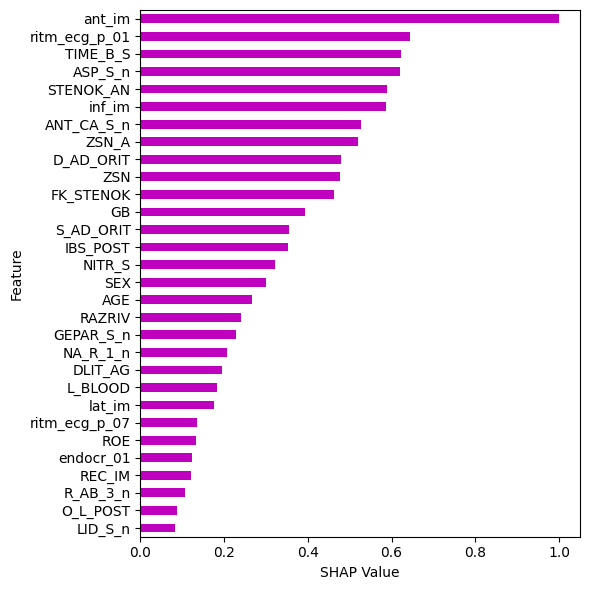

In [80]:
# Create a vertical figure for better spacing
plt.figure(figsize=(6, 6))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized[:30].plot(kind='barh', color='m')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Samplingshap_mic_lr_normalized.eps', format='eps', dpi=300)

plt.show()

Using 1360 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
100%|██████████| 1360/1360 [2:07:08<00:00,  5.61s/it] 


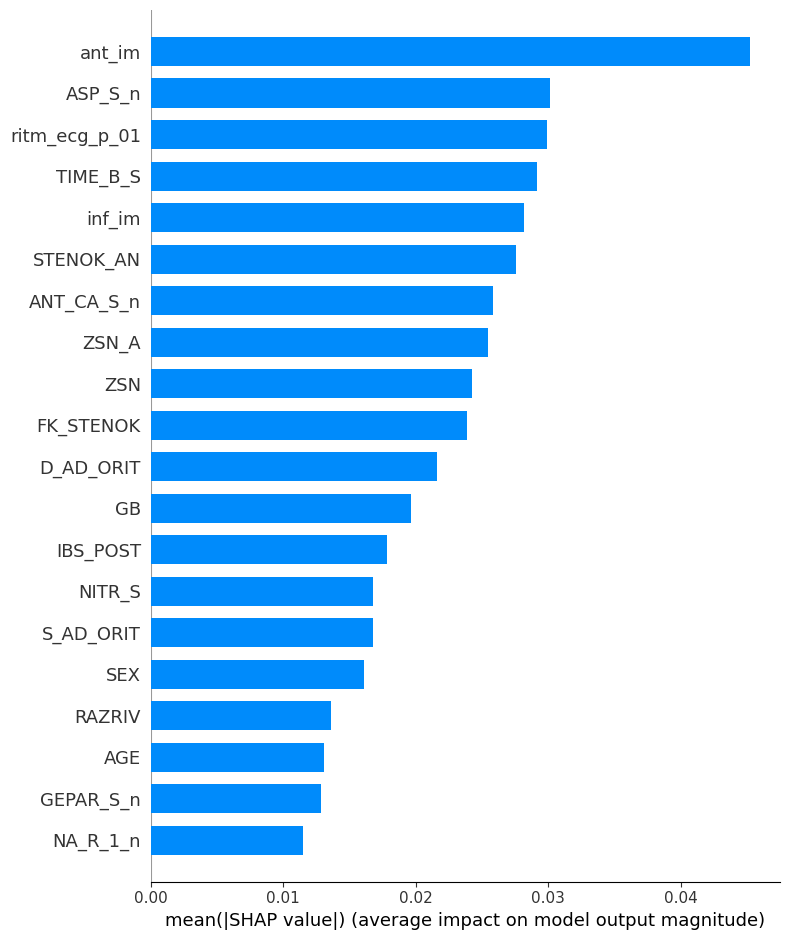

In [69]:
s= time.time()
Kernel_explainer = shap.KernelExplainer(model.predict, X_train) 
Kernel_shap_values = Kernel_explainer.shap_values(X_train) 

# 获取特征名称
feature_names = X_train.columns.tolist()

# 绘制 SHAP 摘要图
shap.summary_plot(Kernel_shap_values, X_train, plot_type="bar", feature_names=feature_names)

In [70]:
e = time.time()
e-s

7628.860660076141

In [71]:
Kernel_feature_importance = np.abs(Kernel_shap_values).mean(axis=0)
Kernel_sorted_feature_indices = np.argsort(Kernel_feature_importance)[::-1]
Kernel_sorted_features = X.columns[Kernel_sorted_feature_indices][:30]
Kernel_sorted_features

Index(['ant_im', 'ASP_S_n', 'ritm_ecg_p_01', 'TIME_B_S', 'inf_im', 'STENOK_AN',
       'ANT_CA_S_n', 'ZSN_A', 'ZSN', 'FK_STENOK', 'D_AD_ORIT', 'GB',
       'IBS_POST', 'NITR_S', 'S_AD_ORIT', 'SEX', 'RAZRIV', 'AGE', 'GEPAR_S_n',
       'NA_R_1_n', 'DLIT_AG', 'L_BLOOD', 'lat_im', 'ritm_ecg_p_07', 'ROE',
       'endocr_01', 'REC_IM', 'R_AB_3_n', 'O_L_POST', 'LID_S_n'],
      dtype='object')

In [81]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(Kernel_shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)
shap_values_per_feature_sorted

ant_im           0.045233
ASP_S_n          0.030101
ritm_ecg_p_01    0.029905
TIME_B_S         0.029159
inf_im           0.028196
                   ...   
np_10            0.001226
n_p_ecg_p_05     0.001217
GT_POST          0.001215
nr_08            0.001132
JELUD_TAH        0.001122
Length: 111, dtype: float64

In [82]:
shap_values_per_feature_sorted[:30]

ant_im           0.045233
ASP_S_n          0.030101
ritm_ecg_p_01    0.029905
TIME_B_S         0.029159
inf_im           0.028196
STENOK_AN        0.027576
ANT_CA_S_n       0.025839
ZSN_A            0.025451
ZSN              0.024285
FK_STENOK        0.023838
D_AD_ORIT        0.021589
GB               0.019675
IBS_POST         0.017870
NITR_S           0.016767
S_AD_ORIT        0.016765
SEX              0.016109
RAZRIV           0.013583
AGE              0.013094
GEPAR_S_n        0.012859
NA_R_1_n         0.011487
DLIT_AG          0.011208
L_BLOOD          0.009893
lat_im           0.009103
ritm_ecg_p_07    0.008256
ROE              0.007922
endocr_01        0.007797
REC_IM           0.007613
R_AB_3_n         0.006937
O_L_POST         0.006246
LID_S_n          0.005743
dtype: float64

In [83]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=False)
shap_values_per_feature_normalized

ant_im           1.000000
ASP_S_n          0.656959
ritm_ecg_p_01    0.652496
TIME_B_S         0.635590
inf_im           0.613770
                   ...   
np_10            0.002362
n_p_ecg_p_05     0.002146
GT_POST          0.002103
nr_08            0.000229
JELUD_TAH        0.000000
Length: 111, dtype: float64

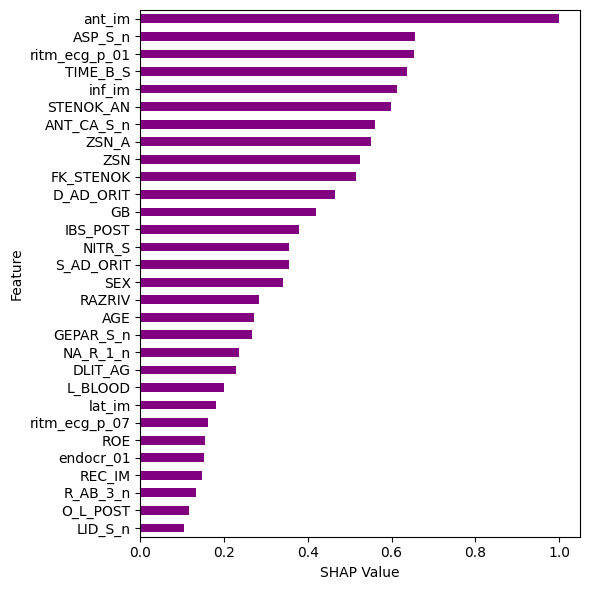

In [84]:
# Create a vertical figure for better spacing
plt.figure(figsize=(6, 6))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized[:30].plot(kind='barh', color='purple')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Kernelshap_mic_lr_normalized.eps', format='eps', dpi=300)

plt.show()